In [1]:
# Run first before importing sklearn estimators
from sklearnex import patch_sklearn
patch_sklearn()

# Core library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik

# Library for Data Split and Pipeline Preprocessing
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, PowerTransformer, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer

# Library for Models and Metrics
import time
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier


from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay



Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


In [ ]:
# Reload the dataset
file_path = r"./Dataset/my_data.csv"
df = pd.read_csv(file_path)

pd.set_option('display.max_columns', None)

df.head()

<>:2: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:2: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
C:\Users\Thinkpad X13\AppData\Local\Temp\ipykernel_40756\1783539365.py:2: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  file_path = ".\Dataset\\my_data.csv"


,customer_id,age,occupation,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,credit_mix,outstanding_debt,credit_utilization_ratio,credit_history_age,payment_of_min_amount,total_emi_per_month,amount_invested_monthly,payment_behaviour,monthly_balance,last_loan_9,last_loan_8,last_loan_7,last_loan_6,last_loan_5,last_loan_4,last_loan_3,last_loan_2,last_loan_1,credit_score,payment_level,payment_volume
0,CUS_0x98ed,31,Journalist,22229.060,1672.421667,6,4,5.0,3,10,10,9.44,9,Standard,1396.14,33.061861,156,Yes,52.138474,44.084010,High_spent_Medium_value_payments,321.019683,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Debt Consolidation Loan,Standard,High payment,Medium payment
1,CUS_0x36b4,43,Musician,17060.705,1685.725417,8,3,11.0,4,24,8,9.64,2,Standard,268.81,36.377621,269,Yes,51.934634,39.628311,Low_spent_Small_value_payments,327.009597,No Loan,No Loan,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Auto Loan,Auto Loan,Standard,Low payment,Small payment
2,CUS_0x105b,24,Accountant,34428.210,2575.017500,2,4,8.0,0,3,12,8.51,0,Good,180.70,39.917508,326,No,0.000000,84.774645,High_spent_Small_value_payments,432.727105,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,Good,High payment,Small payment
3,CUS_0x4c4a,21,Accountant,12613.920,1155.160000,4,6,13.0,3,14,17,17.51,3,Standard,569.11,39.841494,376,Yes,16.941903,41.943603,Low_spent_Medium_value_payments,346.630494,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,Personal Loan,Student Loan,Home Equity Loan,Standard,Low payment,Medium payment
4,CUS_0x612f,31,Journalist,34775.160,3048.930000,7,9,25.0,5,20,20,17.16,6,Bad,3003.45,36.058472,162,Yes,126.596814,67.970377,High_spent_Medium_value_payments,360.325808,No Loan,No Loan,No Loan,No Loan,Auto Loan,Mortgage Loan,Auto Loan,Payday Loan,Not Specified,Poor,High payment,Medium payment


## Feature Engineering

In [3]:
# Create domain-specific variables
df = df.assign(debt_to_income = lambda x: x['total_emi_per_month']/x['monthly_inhand_salary'], # when x in assign(), x is df
                saving_ratio=lambda x: x['monthly_balance'] / x['monthly_inhand_salary']
)

selected_cols = [f'last_loan_{i}' for i in range(1,10)]

dict_loan = {'count_debt_consolidation_loan': 'Debt Consolidation Loan', 'count_auto_loan' : 'Auto Loan',
                'count_no_loan': 'No Loan', 'count_home_equity_loan': 'Home Equity Loan', 'count_not_specified': 'Not Specified',
                'count_personal_loan': 'Personal Loan', 'count_mortgage_loan': 'Mortgage Loan', 'count_credit_builder_loan': 'Credit Builder Loan', 
                'count_payday_loan':'Payday Loan', 'count_student_loan':'Student Loan'}

for key, value in dict_loan.items():
    df[key] = (df[selected_cols] == value).sum(axis = 1)

active_loan_cols = [
    col for col in dict_loan.keys()
    if col not in ['count_no_loan', 'count_not_specified']
]

df['total_active_loans'] = df[active_loan_cols].sum(axis = 1)

# Binary flag indicators

# Red flag
df['has_payday_loan'] = (df['count_payday_loan'] > 0).astype(int)
df['has_home_equity_loan'] = (df['count_home_equity_loan'] > 0).astype(int)
df['has_mortgage_loan'] = (df['count_mortgage_loan'] > 0).astype(int)

# Green flag
df['has_credit_builder_loan'] = (df['count_credit_builder_loan'] > 0).astype(int)

df['high_risk_loan_ratio'] = (df['count_payday_loan'])/(df['total_active_loans'] + 1)

df = df.drop(columns = selected_cols + ['payment_behaviour'])

df.head()

,customer_id,age,occupation,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,credit_mix,outstanding_debt,credit_utilization_ratio,credit_history_age,payment_of_min_amount,total_emi_per_month,amount_invested_monthly,monthly_balance,credit_score,payment_level,payment_volume,debt_to_income,saving_ratio,count_debt_consolidation_loan,count_auto_loan,count_no_loan,count_home_equity_loan,count_not_specified,count_personal_loan,count_mortgage_loan,count_credit_builder_loan,count_payday_loan,count_student_loan,total_active_loans,has_payday_loan,has_home_equity_loan,has_mortgage_loan,has_credit_builder_loan,high_risk_loan_ratio
0,CUS_0x98ed,31,Journalist,22229.060,1672.421667,6,4,5.0,3,10,10,9.44,9,Standard,1396.14,33.061861,156,Yes,52.138474,44.084010,321.019683,Standard,High payment,Medium payment,0.031175,0.191949,2,0,6,1,0,0,0,0,0,0,3,0,1,0,0,0.0
1,CUS_0x36b4,43,Musician,17060.705,1685.725417,8,3,11.0,4,24,8,9.64,2,Standard,268.81,36.377621,269,Yes,51.934634,39.628311,327.009597,Standard,Low payment,Small payment,0.030808,0.193987,1,2,5,1,0,0,0,0,0,0,4,0,1,0,0,0.0
2,CUS_0x105b,24,Accountant,34428.210,2575.017500,2,4,8.0,0,3,12,8.51,0,Good,180.70,39.917508,326,No,0.000000,84.774645,432.727105,Good,High payment,Small payment,0.000000,0.168048,0,0,9,0,0,0,0,0,0,0,0,0,0,0,0,0.0
3,CUS_0x4c4a,21,Accountant,12613.920,1155.160000,4,6,13.0,3,14,17,17.51,3,Standard,569.11,39.841494,376,Yes,16.941903,41.943603,346.630494,Standard,Low payment,Medium payment,0.014666,0.300071,0,0,6,1,0,1,0,0,0,1,3,0,1,0,0,0.0
4,CUS_0x612f,31,Journalist,34775.160,3048.930000,7,9,25.0,5,20,20,17.16,6,Bad,3003.45,36.058472,162,Yes,126.596814,67.970377,360.325808,Poor,High payment,Medium payment,0.041522,0.118181,0,2,4,0,1,0,1,0,1,0,4,1,0,1,0,0.2


ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

In [ ]:
# Mapping target varible
target_map = {'Poor': 0, 'Standard': 1, 'Good': 2}
df['credit_score'] = df['credit_score'].replace(target_map)

In [ ]:
# Check on the values of target variables: Credit_score
print(f'Data type of Credit Score: {df['credit_score'].dtype}\n')
print(f'Unique Values of Credit Score:{df['credit_score'].unique()}\n')
print(f'Number of missing values:{df['credit_score'].isna().sum()}')

Data type of Credit Score: object

Unique Values of Credit Score:[1 2 0]

Number of missing values:0


In [ ]:
# Hyperparameter
y = df['credit_score'].astype('int16')
groups = df['customer_id']
X = df.drop(columns = ['credit_score', 'customer_id'])

params = {'random_state': 42}

In [ ]:
# Splitting original dataset into Dev and Test set
sgkf_test = StratifiedGroupKFold(n_splits = 5, shuffle = True, random_state = params['random_state'])

dev_idx, test_idx = next(sgkf_test.split(X, y, groups = groups))

X_dev, X_test = X.iloc[dev_idx], X.iloc[test_idx]
y_dev, y_test = y.iloc[dev_idx], y.iloc[test_idx]
groups_dev = groups.iloc[dev_idx]

# Splitting Dev set into Train set and Validate set
sgkf_val= StratifiedGroupKFold(n_splits = 4, shuffle = True, random_state = params['random_state'])
train_idx, val_idx = next(sgkf_val.split(X_dev, y_dev, groups = groups_dev))

X_train, X_val = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
y_train, y_val = y_dev.iloc[train_idx], y_dev.iloc[val_idx]

Test Set: 2500
Development Set: 10000
Train Groups: 7500
validate Groups: 2500
There is no duplicated row in Dev and Test Set!
There is no duplicated row in Train and Validate Set!


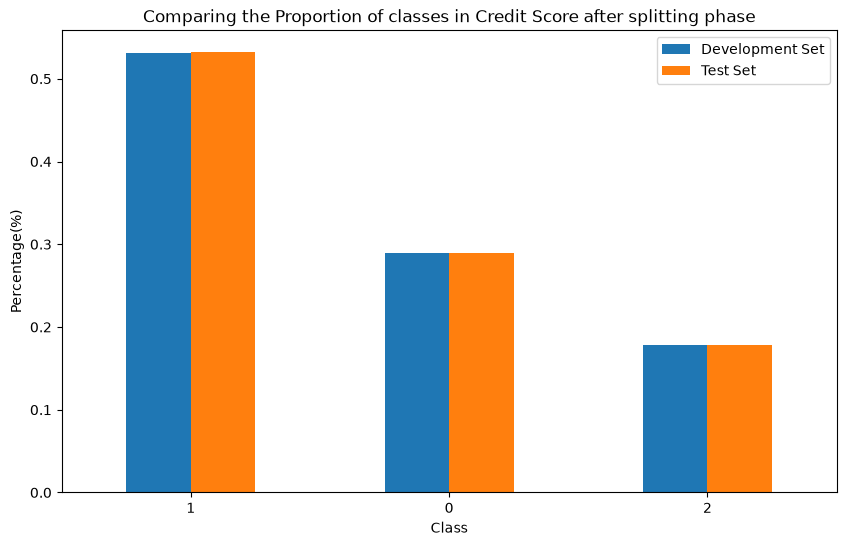

In [ ]:
# Check on the validity after spliting
print(f"Test Set: {groups.iloc[test_idx].nunique()}")
print(f"Development Set: {groups.iloc[dev_idx].nunique()}")
print(f"Train Groups: {groups_dev.iloc[train_idx].nunique()}")
print(f"validate Groups: {groups_dev.iloc[val_idx].nunique()}")

test_customers = set(groups.iloc[test_idx])
dev_customers = set(groups.iloc[dev_idx])
train_customers = set(groups_dev.iloc[train_idx])
val_customers = set(groups_dev.iloc[val_idx])

overlap_dev_test = dev_customers.intersection(test_customers)
overlap_train_val = train_customers.intersection(val_customers)

print(f"Numbers of duplications:{len(overlap_dev_test)}") if len(overlap_dev_test) > 0 else print("There is no duplicated row in Dev and Test Set!")
print(f"Numbers of duplications:{len(overlap_train_val)}") if len(overlap_train_val) > 0 else print("There is no duplicated row in Train and Validate Set!")

# Visualization to check whether Dev and Test set have the same proportion in target's classes
dev_counts = y_dev.value_counts(normalize = True)
test_counts = y_test.value_counts(normalize = True)

df_compared = pd.DataFrame({'Development Set':dev_counts, 'Test Set': test_counts})
df_compared.plot(kind = 'bar', figsize =(10,6))

plt.title('Comparing the Proportion of classes in Credit Score after splitting phase')
plt.xlabel('Class')
plt.ylabel('Percentage(%)')
plt.xticks(rotation = 0)

plt.show()

## Pipeline Preprocessing Initialization

In [ ]:
# Skewed-right variables

# Only numeric (disc/cont) variables having range > 50 and skewness > 1 (extremely skewed)
dis_ratio_var = ['age', 'num_bank_accounts','num_credit_card','num_of_loan','delay_from_due_date','num_of_delayed_payment',
                    'num_credit_inquiries','credit_history_age','count_debt_consolidation_loan', 'count_auto_loan', 'count_no_loan',
                    'count_home_equity_loan', 'count_not_specified', 'count_personal_loan',
                    'count_mortgage_loan', 'count_credit_builder_loan', 'count_payday_loan',
                    'count_student_loan', 'total_active_loans', 'has_payday_loan',
                    'has_home_equity_loan', 'has_mortgage_loan', 'has_credit_builder_loan']

con_ratio_var = ['annual_income','monthly_inhand_salary','interest_rate','changed_credit_limit','outstanding_debt',
                'credit_utilization_ratio','total_emi_per_month','amount_invested_monthly','monthly_balance', 'debt_to_income',
                'saving_ratio','high_risk_loan_ratio']

numeric_col = dis_ratio_var + con_ratio_var

range_values = X_train[numeric_col].max() - X_train[numeric_col].min()
skew_values = X_train[numeric_col].skew()
skewed_features = skew_values[(range_values > 50) & (skew_values > 1)].index.tolist()

print(f"Variables needing to be log transformed are: {skewed_features}")

# Normal numeric variables
num_cols = [col for col in numeric_col if col not in skewed_features]

# Non-numeric variables
str_cols = X_train.select_dtypes(exclude = 'number').columns.tolist()

credit_mix_ord = ['Bad', 'Standard', 'Good']
payment_level_ord = ['Low payment', 'High payment']
payment_volume_ord = ['Small payment', 'Medium payment', 'Large payment']

nom_cols = ['occupation', 'payment_of_min_amount']

ord_cols = ['credit_mix', 'payment_level', 'payment_volume']

# Create pipeline
nom_pipeline = Pipeline(steps = [('imputer', SimpleImputer(strategy = 'most_frequent')),
                                 ('onehot', OneHotEncoder(handle_unknown = 'ignore', sparse_output = False))])

ord_pipeline = Pipeline(steps = [('imputer', SimpleImputer(strategy = 'most_frequent')),
                                 ('custom_mapper', OrdinalEncoder(
                                                    categories = [credit_mix_ord, payment_level_ord, payment_volume_ord],
                                                    handle_unknown = 'use_encoded_value',
                                                    unknown_value = -1))])

yeo_johnson_pipeline = Pipeline(steps = [('imputer', SimpleImputer(strategy = 'median')),
                                         ('yeo_johnson', PowerTransformer(method = 'yeo-johnson', standardize=True))])

num_pipeline = Pipeline(steps = [('imputer', SimpleImputer(strategy = 'mean')),
                                 ('scaler', StandardScaler())])

preprocessor = ColumnTransformer(
    transformers = [
        ('nom_branch', nom_pipeline, nom_cols),
        ('ord_branch', ord_pipeline, ord_cols),
        ('yeo_johnson_branch', yeo_johnson_pipeline, skewed_features),
        ('num_branch', num_pipeline, num_cols)
    ],
    remainder = 'drop'
)

full_pipeline = Pipeline(steps = [
    ('preprocessing', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators= 100, class_weight = 'balanced',
                                    random_state= params['random_state'], n_jobs = -1))
])

Variables needing to be log transformed are: ['annual_income', 'monthly_inhand_salary', 'outstanding_debt', 'total_emi_per_month', 'amount_invested_monthly', 'monthly_balance']


In [ ]:
models = {
    "Most Frequent (Baseline)": DummyClassifier(
        strategy = "most_frequent"
    ),
    "Logistic Regression": LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=params['random_state']
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=params['random_state'],
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=params['random_state']
    ),
    "LightGBM": LGBMClassifier(
        objective='multiclass',
        class_weight='balanced',
        random_state=params['random_state'],
        n_jobs=-1,
        verbose=-1
    ),
    "XGBoost": XGBClassifier(
        objective='multi:softprob',
        random_state=params['random_state'],
        n_jobs=-1,
        eval_metric='mlogloss'
    )
}

In [ ]:
scoring_metrics = {
    'accuracy':'accuracy',
    'f1_macro':'f1_macro',
    'roc_auc_ovr':'roc_auc_ovr'
}

benchmark_summary = []
fold_details = []

for name, clf in models.items():
    print(f"Training and Evaluating with {name}")
    model_pipeline = Pipeline(steps=[
        ('preprocessing', preprocessor),
        ('classifier', clf)
    ])


    benchmark_summary.append({
        'Model':name,
        'Train F1-Macro':cv_out['train_f1_macro'].mean(),
        'Val F1-Macro (Mean)': cv_out['test_f1_macro'].mean(),
        'Val F1-Macro (Std)': cv_out['test_f1_macro'].std(),
        'Val Accuracy': cv_out['test_accuracy'].mean(),
        'Val ROC-AUC (OvR)':cv_out['test_roc_auc_ovr'].mean(),
        'Fit Time (s)':cv_out['fit_time'].mean()
    })

    for fold_i, f1_val in enumerate(cv_out['test_f1_macro']):
        fold_details.append({
            'Model':name,
            'Fold': fold_i + 1,
            'Val F1-Macro': f1_val
        })

df_benchmark = pd.DataFrame(benchmark_summary).sort_values(by='Val F1-Macro (Mean)', ascending = False)
df_fold_details = pd.DataFrame(fold_details)

display(df_benchmark.reset_index(drop=True))

Training and Evaluating with Random Forest (Baseline)...
Training and Evaluating with Logistic Regression...
Training and Evaluating with Extra Trees...
Training and Evaluating with LightGBM...
Training and Evaluating with XGBoost...


,Model,Train F1-Macro,Val F1-Macro (Mean),Val F1-Macro (Std),Val Accuracy,Val ROC-AUC (OvR),Fit Time (s)
0,LightGBM,0.759231,0.679757,0.004048,0.687538,0.847804,30.089094
1,Random Forest (Baseline),0.962095,0.674478,0.003281,0.680688,NaN,66.585650
2,XGBoost,0.847244,0.669168,0.003388,0.694163,0.842588,24.466357
3,Extra Trees,0.997324,0.664436,0.002961,0.671175,NaN,76.091591
4,Logistic Regression,0.650902,0.648919,0.004293,0.655275,0.809510,13.191417


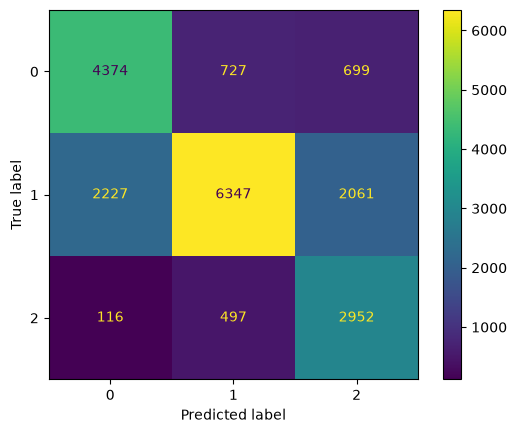

Classification Repor for Evaluation
              precision    recall  f1-score   support

           0       0.65      0.75      0.70      5800
           1       0.84      0.60      0.70     10635
           2       0.52      0.83      0.64      3565

    accuracy                           0.68     20000
   macro avg       0.67      0.73      0.68     20000
weighted avg       0.73      0.68      0.69     20000

Classification Repor for Final Test
              precision    recall  f1-score   support

           0       0.65      0.74      0.69      5798
           1       0.84      0.60      0.70     10635
           2       0.51      0.83      0.63      3567

    accuracy                           0.68     20000
   macro avg       0.67      0.72      0.67     20000
weighted avg       0.73      0.68      0.68     20000

Test ROC-AUC (Macro OvR): 0.8391


In [ ]:
full_pipeline.fit(X_train, y_train)

y_val_pred = full_pipeline.predict(X_val)
y_val_proba = full_pipeline.predict_proba(X_val)

cm = confusion_matrix(y_val, y_val_pred) 
disp = ConfusionMatrixDisplay(confusion_matrix = cm)
disp.plot()
plt.show()
print("Classification Report for Evaluation")
print(classification_report(y_val, y_val_pred))

y_test_pred = full_pipeline.predict(X_test)
y_test_proba = full_pipeline.predict_proba(X_test)

print("Classification Report for Final Test")
print(classification_report(y_test, y_test_pred))

from sklearn.metrics import roc_auc_score

# Tính ROC-AUC theo chiến lược One-vs-Rest (OvR)
auc_score = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='macro')
print(f"Test ROC-AUC (Macro OvR): {auc_score:.4f}")

### Correlation between type of feature variables and target variable

In [ ]:
# # Prepare dataframe for creating heatmaps
# all_numeric_cols = [
#     'credit_score', 'credit_mix', 'payment_level', 'payment_volume', 
#     'annual_income', 'monthly_inhand_salary', 'outstanding_debt', 'delay_from_due_date', 
#     'credit_utilization_ratio', 'num_of_delayed_payment', 
#     'credit_history_age', 'total_emi_per_month', 'amount_invested_monthly'
# ]

# spearman_corr = df[all_numeric_cols].corr(method='spearman')

# plt.figure(figsize=(10, 8))
# sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
# plt.title("Unified Spearman Correlation Heatmap", fontsize=14, fontweight='bold')
# plt.tight_layout()
# plt.show()

# # Target correlation plot

# target_corr = spearman_corr[['credit_score']].drop(index = 'credit_score').sort_values(by = 'credit_score', ascending = False)
# plt.figure(figsize=(8,6))

# sns.barplot(data = target_corr, x = 'credit_score', y = target_corr.index, palette = 'coolwarm', hue = target_corr.index)
# plt.title("Spearman Correlation of Features with Credit Score")
# plt.xlabel("Spearman Correlation Coefficients")
# plt.ylabel("Feature variable")

# plt.grid(True, linestyle = '-.', alpha = 0.75)
# plt.show()

# # Using phik to check correlation between nominal and target variables

# phik_temp1 = df[['credit_score', 'payment_volume', 'payment_level', 'credit_mix']]
# phik_temp2 = df[['occupation', 'payment_behaviour']]
# phik_matrix = pd.concat([phik_temp1, phik_temp2], axis = 1).phik_matrix()

# plt.figure(figsize = (8, 5))
# sns.heatmap(data = phik_matrix, annot = True, fmt = '.2f', cmap = 'Blues')
# plt.title('Phik Correlation Heatmap between Categorical and Target variable', fontweight = 'bold')
# plt.show()